# A8v2. Построение large-scale модели высокочастотного радиоканала 6G/IMT-2030 и link-budget анализ

**Среда:** Python + Google Colab  
**Продолжительность:** 2 часа  
**Вариант:** `VARIANT = 1..15`

Базовая модель использует 3GPP TR 38.901 UMi Street Canyon large-scale path loss, shadow fading и oxygen absorption в диапазоне 0.5–100 GHz. A8v2 проверяет Monte Carlo результат аналитической формулой outage, рассчитывает 95% confidence interval и coverage-radius KPI. Выше 100 GHz используется только exploratory FSPL extension, который не интерпретируется как модель 38.901.


## 1. Функции модели и 15 вариантов

In [1]:
import matplotlib.pyplot as plt
import math
import numpy as np
import pandas as pd

C_MPS = 299_792_458.0
H_BS_M = 10.0
H_UT_M = 1.5

# TR 38.901 Table 7.6.1-1 teaching lookup, dB/km.
_OXY_FREQ = np.array([0.0, 52.0, 53.0, 54.0, 55.0, 56.0, 57.0, 58.0, 59.0, 60.0, 61.0, 62.0, 63.0, 64.0, 65.0, 66.0, 67.0, 68.0, 100.0])
_OXY_ALPHA = np.array([0.0, 0.0, 1.0, 2.2, 4.0, 6.6, 9.7, 12.6, 14.6, 15.0, 14.6, 14.3, 10.5, 6.8, 3.9, 1.9, 1.0, 0.0, 0.0])

VARIANTS = [
    dict(variant=1,  frequency_ghz=60.0, condition='NLOS', distance_m=100.0, max_distance_m=300.0, ptx_dbm=30.0, gtx_dbi=18.0, grx_dbi=8.0,  bandwidth_mhz=400.0,  noise_figure_db=7.0, snr_threshold_db=0.0,  seed=701),
    dict(variant=2,  frequency_ghz=28.0, condition='LOS',  distance_m=150.0, max_distance_m=400.0, ptx_dbm=30.0, gtx_dbi=16.0, grx_dbi=6.0,  bandwidth_mhz=200.0,  noise_figure_db=6.0, snr_threshold_db=5.0,  seed=702),
    dict(variant=3,  frequency_ghz=39.0, condition='NLOS', distance_m=120.0, max_distance_m=350.0, ptx_dbm=30.0, gtx_dbi=18.0, grx_dbi=8.0,  bandwidth_mhz=400.0,  noise_figure_db=7.0, snr_threshold_db=0.0,  seed=703),
    dict(variant=4,  frequency_ghz=73.0, condition='NLOS', distance_m=80.0,  max_distance_m=250.0, ptx_dbm=28.0, gtx_dbi=22.0, grx_dbi=10.0, bandwidth_mhz=800.0,  noise_figure_db=8.0, snr_threshold_db=0.0,  seed=704),
    dict(variant=5,  frequency_ghz=90.0, condition='LOS',  distance_m=150.0, max_distance_m=350.0, ptx_dbm=30.0, gtx_dbi=24.0, grx_dbi=10.0, bandwidth_mhz=1000.0, noise_figure_db=8.0, snr_threshold_db=3.0,  seed=705),
    dict(variant=6,  frequency_ghz=100.0,condition='NLOS', distance_m=60.0,  max_distance_m=200.0, ptx_dbm=28.0, gtx_dbi=26.0, grx_dbi=12.0, bandwidth_mhz=1000.0, noise_figure_db=8.0, snr_threshold_db=0.0,  seed=706),
    dict(variant=7,  frequency_ghz=60.0, condition='LOS',  distance_m=250.0, max_distance_m=500.0, ptx_dbm=27.0, gtx_dbi=18.0, grx_dbi=8.0,  bandwidth_mhz=400.0,  noise_figure_db=7.0, snr_threshold_db=5.0,  seed=707),
    dict(variant=8,  frequency_ghz=28.0, condition='NLOS', distance_m=200.0, max_distance_m=500.0, ptx_dbm=30.0, gtx_dbi=20.0, grx_dbi=8.0,  bandwidth_mhz=200.0,  noise_figure_db=6.0, snr_threshold_db=-2.0, seed=708),
    dict(variant=9,  frequency_ghz=39.0, condition='LOS',  distance_m=300.0, max_distance_m=600.0, ptx_dbm=30.0, gtx_dbi=18.0, grx_dbi=8.0,  bandwidth_mhz=400.0,  noise_figure_db=7.0, snr_threshold_db=5.0,  seed=709),
    dict(variant=10, frequency_ghz=73.0, condition='LOS',  distance_m=200.0, max_distance_m=450.0, ptx_dbm=28.0, gtx_dbi=22.0, grx_dbi=10.0, bandwidth_mhz=800.0,  noise_figure_db=8.0, snr_threshold_db=3.0,  seed=710),
    dict(variant=11, frequency_ghz=90.0, condition='NLOS', distance_m=80.0,  max_distance_m=250.0, ptx_dbm=30.0, gtx_dbi=26.0, grx_dbi=12.0, bandwidth_mhz=1000.0, noise_figure_db=8.0, snr_threshold_db=0.0,  seed=711),
    dict(variant=12, frequency_ghz=100.0,condition='LOS',  distance_m=180.0, max_distance_m=400.0, ptx_dbm=30.0, gtx_dbi=28.0, grx_dbi=12.0, bandwidth_mhz=1000.0, noise_figure_db=8.0, snr_threshold_db=3.0,  seed=712),
    dict(variant=13, frequency_ghz=60.0, condition='NLOS', distance_m=150.0, max_distance_m=400.0, ptx_dbm=30.0, gtx_dbi=22.0, grx_dbi=10.0, bandwidth_mhz=800.0,  noise_figure_db=8.0, snr_threshold_db=0.0,  seed=713),
    dict(variant=14, frequency_ghz=28.0, condition='LOS',  distance_m=400.0, max_distance_m=800.0, ptx_dbm=33.0, gtx_dbi=18.0, grx_dbi=8.0,  bandwidth_mhz=100.0,  noise_figure_db=6.0, snr_threshold_db=0.0,  seed=714),
    dict(variant=15, frequency_ghz=73.0, condition='NLOS', distance_m=100.0, max_distance_m=300.0, ptx_dbm=30.0, gtx_dbi=24.0, grx_dbi=10.0, bandwidth_mhz=1000.0, noise_figure_db=8.0, snr_threshold_db=-2.0, seed=715),
]


def _check_fc(fc):
    fc = float(fc)
    if not (0.5 <= fc <= 100.0):
        raise ValueError('TR 38.901 core model requires 0.5 <= frequency_ghz <= 100')
    return fc


def d3d_m(distance_2d_m, h_bs_m=H_BS_M, h_ut_m=H_UT_M):
    d2 = float(distance_2d_m)
    if d2 <= 0:
        raise ValueError('distance must be positive')
    return math.sqrt(d2*d2 + (float(h_bs_m)-float(h_ut_m))**2)


def fspl_db(frequency_ghz, distance_m):
    fc = float(frequency_ghz)
    d = float(distance_m)
    if fc <= 0 or d <= 0:
        raise ValueError('frequency and distance must be positive')
    return 32.4 + 20.0*math.log10(d) + 20.0*math.log10(fc)


def oxygen_alpha_db_per_km(frequency_ghz):
    fc = _check_fc(frequency_ghz)
    return float(np.interp(fc, _OXY_FREQ, _OXY_ALPHA))


def oxygen_loss_proxy_db(frequency_ghz, distance_m):
    # Scalar large-scale teaching proxy using direct geometric distance only.
    return oxygen_alpha_db_per_km(frequency_ghz) * float(distance_m) / 1000.0


def umi_breakpoint_m(frequency_ghz, h_bs_m=H_BS_M, h_ut_m=H_UT_M, h_e_m=1.0):
    fc_hz = _check_fc(frequency_ghz)*1e9
    hbs_eff = max(float(h_bs_m)-float(h_e_m), 1e-6)
    hut_eff = max(float(h_ut_m)-float(h_e_m), 1e-6)
    return 4.0*hbs_eff*hut_eff*fc_hz/C_MPS


def umi_pathloss_db(frequency_ghz, distance_2d_m, condition='LOS', h_bs_m=H_BS_M, h_ut_m=H_UT_M):
    fc = _check_fc(frequency_ghz)
    d2 = float(distance_2d_m)
    if not (10.0 <= d2 <= 5000.0):
        raise ValueError('UMi Street Canyon teaching implementation requires 10 <= d2D <= 5000 m')
    d3 = d3d_m(d2, h_bs_m, h_ut_m)
    dbp = umi_breakpoint_m(fc, h_bs_m, h_ut_m, h_e_m=1.0)
    if d2 <= dbp:
        pl_los = 32.4 + 21.0*math.log10(d3) + 20.0*math.log10(fc)
    else:
        pl_los = (32.4 + 40.0*math.log10(d3) + 20.0*math.log10(fc)
                  - 9.5*math.log10(dbp**2 + (float(h_bs_m)-float(h_ut_m))**2))
    cond = str(condition).upper()
    if cond == 'LOS':
        return float(pl_los)
    if cond != 'NLOS':
        raise ValueError("condition must be 'LOS' or 'NLOS'")
    pl_nlos_prime = (22.4 + 35.3*math.log10(d3) + 21.3*math.log10(fc)
                     - 0.3*(float(h_ut_m)-1.5))
    return float(max(pl_los, pl_nlos_prime))


def shadow_sigma_db(condition):
    cond = str(condition).upper()
    if cond == 'LOS':
        return 4.0
    if cond == 'NLOS':
        return 7.82
    raise ValueError("condition must be 'LOS' or 'NLOS'")


def noise_power_dbm(bandwidth_mhz, noise_figure_db):
    bw_hz = float(bandwidth_mhz)*1e6
    if bw_hz <= 0:
        raise ValueError('bandwidth must be positive')
    return -174.0 + 10.0*math.log10(bw_hz) + float(noise_figure_db)


def deterministic_link_budget(v):
    fc = _check_fc(v['frequency_ghz'])
    d2 = float(v['distance_m'])
    cond = str(v['condition']).upper()
    d3 = d3d_m(d2)
    pl_umi = umi_pathloss_db(fc, d2, cond)
    alpha = oxygen_alpha_db_per_km(fc)
    oxy = oxygen_loss_proxy_db(fc, d3)
    pl_total = pl_umi + oxy
    rx = float(v['ptx_dbm']) + float(v['gtx_dbi']) + float(v['grx_dbi']) - pl_total
    noise = noise_power_dbm(v['bandwidth_mhz'], v['noise_figure_db'])
    snr = rx - noise
    return {
        'frequency_ghz':fc, 'condition':cond, 'distance_2d_m':d2, 'distance_3d_m':d3,
        'fspl_db':fspl_db(fc,d3), 'pathloss_umi_db':pl_umi,
        'oxygen_alpha_db_per_km':alpha, 'oxygen_loss_db':oxy,
        'pathloss_total_db':pl_total, 'ptx_dbm':float(v['ptx_dbm']),
        'gtx_dbi':float(v['gtx_dbi']), 'grx_dbi':float(v['grx_dbi']),
        'bandwidth_mhz':float(v['bandwidth_mhz']), 'noise_figure_db':float(v['noise_figure_db']),
        'noise_dbm':noise, 'rx_power_dbm':rx, 'snr_db':snr,
        'snr_threshold_db':float(v['snr_threshold_db']),
        'link_margin_db':snr-float(v['snr_threshold_db']),
        'shadow_sigma_db':shadow_sigma_db(cond),
    }


def monte_carlo_samples(v, n_samples=10000, z_samples=None):
    base = deterministic_link_budget(v)
    n = int(n_samples)
    if n <= 0:
        raise ValueError('n_samples must be positive')
    if z_samples is None:
        rng = np.random.default_rng(int(v['seed']))
        z = rng.normal(0.0, 1.0, n)
    else:
        z = np.asarray(z_samples, dtype=float)
        n = len(z)
    sf = z * base['shadow_sigma_db']
    pl = base['pathloss_total_db'] + sf
    rx = float(v['ptx_dbm']) + float(v['gtx_dbi']) + float(v['grx_dbi']) - pl
    snr = rx - base['noise_dbm']
    return pd.DataFrame({'z':z,'shadow_fading_db':sf,'pathloss_db':pl,'rx_power_dbm':rx,'snr_db':snr})


def analytical_coverage(v):
    base = deterministic_link_budget(v)
    sigma = float(base['shadow_sigma_db'])
    margin = float(base['snr_db'] - v['snr_threshold_db'])
    if sigma <= 0:
        pcov = 1.0 if margin >= 0 else 0.0
    else:
        # Normal CDF without scipy dependency.
        pcov = 0.5 * (1.0 + math.erf(margin/(sigma*math.sqrt(2.0))))
    return {'analytical_coverage_probability':pcov,
            'analytical_outage_probability':1.0-pcov}


def wilson_ci(k, n, z=1.96):
    if n <= 0: return (float('nan'), float('nan'))
    p = k/n
    den = 1.0 + z*z/n
    center = (p + z*z/(2*n))/den
    half = z*math.sqrt((p*(1-p)+z*z/(4*n))/n)/den
    return max(0.0, center-half), min(1.0, center+half)


def monte_carlo_link(v, n_samples=10000, z_samples=None):
    df = monte_carlo_samples(v, n_samples=n_samples, z_samples=z_samples)
    th = float(v['snr_threshold_db'])
    outage_mask = df['snr_db'].to_numpy() < th
    outage = float(outage_mask.mean())
    n=len(df); k_cov=int((~outage_mask).sum())
    lo,hi=wilson_ci(k_cov,n)
    ana=analytical_coverage(v)
    return {
        'n_samples':n,
        'median_rx_power_dbm':float(np.median(df['rx_power_dbm'])),
        'p5_rx_power_dbm':float(np.percentile(df['rx_power_dbm'],5)),
        'p95_rx_power_dbm':float(np.percentile(df['rx_power_dbm'],95)),
        'median_snr_db':float(np.median(df['snr_db'])),
        'p5_snr_db':float(np.percentile(df['snr_db'],5)),
        'p95_snr_db':float(np.percentile(df['snr_db'],95)),
        'outage_probability':outage,
        'coverage_probability':1.0-outage,
        'coverage_ci95_low':lo,
        'coverage_ci95_high':hi,
        **ana,
        'mc_minus_analytical_pp':100.0*((1.0-outage)-ana['analytical_coverage_probability']),
    }


def distance_sweep(v, distances_m=None):
    if distances_m is None:
        distances_m = np.linspace(10.0, float(v.get('max_distance_m',500.0)), 80)
    rows=[]
    for d in distances_m:
        vv=dict(v); vv['distance_m']=float(d)
        b=deterministic_link_budget(vv); a=analytical_coverage(vv)
        rows.append({**b, **a})
    return pd.DataFrame(rows)


def coverage_radius(v, target_coverage=0.95, d_min=10.0, d_max=None, n_grid=2500):
    if d_max is None: d_max=float(v.get('max_distance_m',500.0))
    ds=np.linspace(float(d_min),float(d_max),int(n_grid))
    pc=[]
    for d in ds:
        vv=dict(v); vv['distance_m']=float(d)
        pc.append(analytical_coverage(vv)['analytical_coverage_probability'])
    pc=np.asarray(pc)
    ok=np.where(pc>=float(target_coverage))[0]
    return float(ds[ok[-1]]) if len(ok) else float('nan')


def coverage_radii(v):
    return {f'd{int(t*100)}_m':coverage_radius(v,t) for t in (0.50,0.90,0.95)}


def frequency_sensitivity(v, frequencies_ghz=(28.0,39.0,60.0,73.0,90.0,100.0)):
    rows=[]
    for fc in frequencies_ghz:
        vv=dict(v); vv['frequency_ghz']=float(fc)
        rows.append({**deterministic_link_budget(vv), **analytical_coverage(vv)})
    return pd.DataFrame(rows)


def gain_sensitivity(v, total_gain_offsets_db=(-10,-5,0,5,10), n_samples=10000):
    # Common random numbers: the same standardized shadowing samples are reused.
    rng=np.random.default_rng(int(v['seed']))
    z=rng.normal(0.0,1.0,int(n_samples))
    rows=[]
    for off in total_gain_offsets_db:
        vv=dict(v); vv['gtx_dbi']=float(v['gtx_dbi'])+float(off)
        mc=monte_carlo_link(vv,n_samples=n_samples,z_samples=z)
        rows.append({'gain_offset_db':float(off), **mc})
    return pd.DataFrame(rows)


def fixed_eirp_gain_note(v, total_gain_offsets_db=(-10,-5,0,5,10)):
    # At fixed EIRP, increasing Gtx is offset by lower conducted Ptx, so ideal link budget is unchanged.
    eirp=float(v['ptx_dbm'])+float(v['gtx_dbi'])
    rows=[]
    for off in total_gain_offsets_db:
        vv=dict(v)
        vv['gtx_dbi']=float(v['gtx_dbi'])+float(off)
        vv['ptx_dbm']=eirp-vv['gtx_dbi']
        b=deterministic_link_budget(vv)
        rows.append({'gain_offset_db':off,'ptx_dbm_fixed_eirp':vv['ptx_dbm'],'eirp_dbm':eirp,'snr_db':b['snr_db']})
    return pd.DataFrame(rows)


def all_variants_qa(n_samples=1000):
    rows=[]
    for v0 in VARIANTS:
        v=dict(v0)
        try:
            base=deterministic_link_budget(v); mc=monte_carlo_link(v,n_samples=n_samples)
            ok=(0.5 <= v['frequency_ghz'] <= 100.0 and v['condition'] in ('LOS','NLOS') and
                np.isfinite(base['pathloss_total_db']) and np.isfinite(base['snr_db']) and
                0.0 <= mc['coverage_probability'] <= 1.0 and
                abs(mc['coverage_probability']+mc['outage_probability']-1.0)<1e-12)
            note='' if ok else 'range/accounting check failed'
        except Exception as e:
            ok=False; note=str(e); base={'snr_db':np.nan}; mc={'coverage_probability':np.nan}
        rows.append({'variant':v['variant'],'frequency_ghz':v['frequency_ghz'],'condition':v['condition'],
                     'distance_m':v['distance_m'],'snr_db':base['snr_db'],
                     'coverage_probability':mc['coverage_probability'],'ok':ok,'note':note})
    return pd.DataFrame(rows)


## 2. Выбор варианта и базовый link budget

In [2]:
VARIANT = 1
v = dict(VARIANTS[VARIANT-1])
base = deterministic_link_budget(v)
mc = monte_carlo_link(v, n_samples=10000)
radii = coverage_radii(v)

display(pd.DataFrame([v]))
display(pd.DataFrame([base]).round(4))
display(pd.DataFrame([mc])[[
    'median_rx_power_dbm','p5_rx_power_dbm','median_snr_db','p5_snr_db',
    'coverage_probability','coverage_ci95_low','coverage_ci95_high',
    'analytical_coverage_probability','mc_minus_analytical_pp','outage_probability'
]].round(5))
display(pd.DataFrame([radii]).round(2))
print('Примечание: analytical coverage получен из Gaussian shadow-fading формулы, Monte Carlo — по 10 000 реализациям.')


,variant,frequency_ghz,condition,distance_m,max_distance_m,ptx_dbm,gtx_dbi,grx_dbi,bandwidth_mhz,noise_figure_db,snr_threshold_db,seed
0,1,60.0,NLOS,100.0,300.0,30.0,18.0,8.0,400.0,7.0,0.0,701


,frequency_ghz,condition,distance_2d_m,distance_3d_m,fspl_db,pathloss_umi_db,oxygen_alpha_db_per_km,oxygen_loss_db,pathloss_total_db,ptx_dbm,gtx_dbi,grx_dbi,bandwidth_mhz,noise_figure_db,noise_dbm,rx_power_dbm,snr_db,snr_threshold_db,link_margin_db,shadow_sigma_db
0,60.0,NLOS,100.0,100.3606,107.9943,130.9298,15.0,1.5054,132.4352,30.0,18.0,8.0,400.0,7.0,-80.9794,-76.4352,4.5442,0.0,4.5442,7.82


,median_rx_power_dbm,p5_rx_power_dbm,median_snr_db,p5_snr_db,coverage_probability,coverage_ci95_low,coverage_ci95_high,analytical_coverage_probability,mc_minus_analytical_pp,outage_probability
0,-76.47462,-89.4277,4.50478,-8.4483,0.7215,0.71263,0.7302,0.71941,0.20872,0.2785


,d50_m,d90_m,d95_m
0,130.69,71.62,60.02


Примечание: analytical coverage получен из Gaussian shadow-fading формулы, Monte Carlo — по 10 000 реализациям.


## 3. Визуализация: расстояние, поглощение кислорода, SNR и усиление антенны

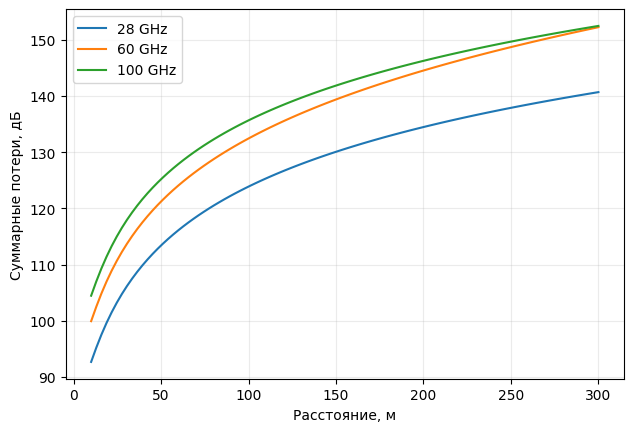

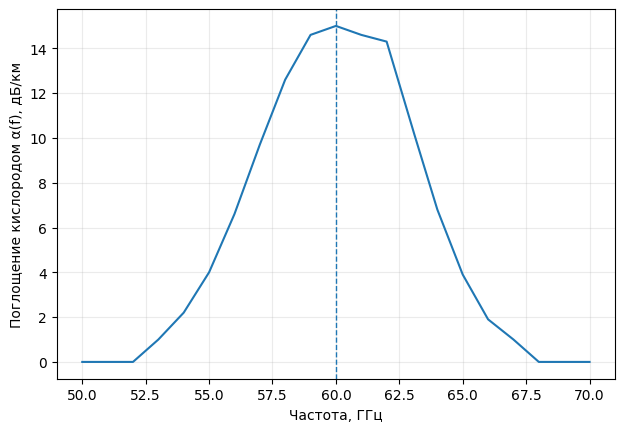

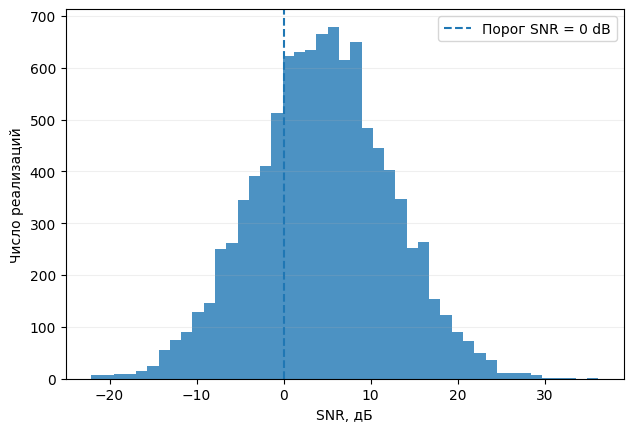

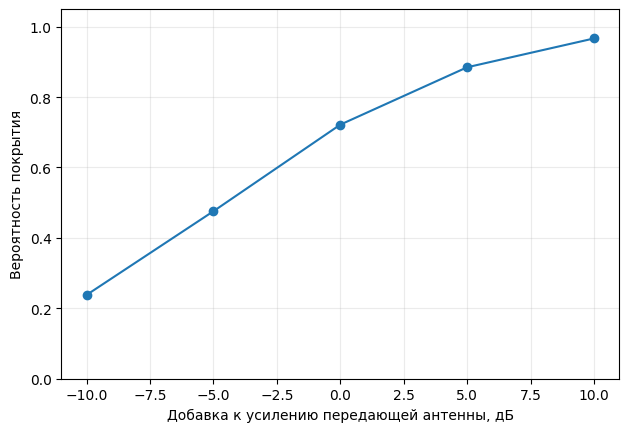

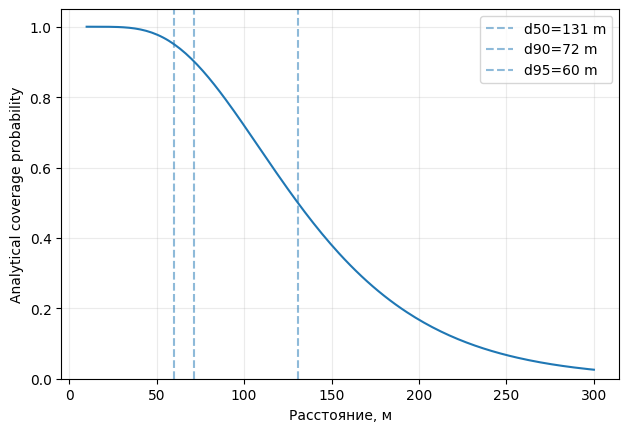

In [3]:
# 1) NLOS path loss: 28/60/100 GHz
D = np.linspace(10, float(v['max_distance_m']), 100)
plt.figure(figsize=(7.2,4.8))
for fc in (28.0,60.0,100.0):
    vals=[]
    for d in D:
        vv=dict(v); vv['frequency_ghz']=fc; vv['distance_m']=float(d); vv['condition']='NLOS'
        vals.append(deterministic_link_budget(vv)['pathloss_total_db'])
    plt.plot(D,vals,label=f'{fc:g} GHz')
plt.xlabel('Расстояние, м'); plt.ylabel('Суммарные потери, дБ'); plt.legend(); plt.grid(alpha=.25); plt.show()

# 2) Oxygen absorption
F=np.arange(50,70.01,0.1)
A=[oxygen_alpha_db_per_km(f) for f in F]
plt.figure(figsize=(7.2,4.8)); plt.plot(F,A); plt.axvline(60,linestyle='--',linewidth=1)
plt.xlabel('Частота, ГГц'); plt.ylabel('Поглощение кислородом α(f), дБ/км'); plt.grid(alpha=.25); plt.show()

# 3) Variant SNR Monte Carlo
samples=monte_carlo_samples(v,10000)
plt.figure(figsize=(7.2,4.8)); plt.hist(samples['snr_db'],bins=45,alpha=.8)
plt.axvline(v['snr_threshold_db'],linestyle='--',linewidth=1.5,label=f"Порог SNR = {v['snr_threshold_db']:.0f} dB")
plt.xlabel('SNR, дБ'); plt.ylabel('Число реализаций'); plt.legend(); plt.grid(axis='y',alpha=.2); plt.show()

# 4) Gain sensitivity
gain_df=gain_sensitivity(v,[-10,-5,0,5,10],10000)
plt.figure(figsize=(7.2,4.8)); plt.plot(gain_df['gain_offset_db'],gain_df['coverage_probability'],marker='o')
plt.xlabel('Добавка к усилению передающей антенны, дБ'); plt.ylabel('Вероятность покрытия'); plt.ylim(0,1.05); plt.grid(alpha=.25); plt.show()

# 5) Analytical coverage vs distance and target radii
dcov=distance_sweep(v,np.linspace(10,float(v['max_distance_m']),180))
plt.figure(figsize=(7.2,4.8)); plt.plot(dcov['distance_2d_m'],dcov['analytical_coverage_probability'])
for t in (0.50,0.90,0.95):
    r=coverage_radius(v,t)
    if np.isfinite(r): plt.axvline(r,linestyle='--',alpha=.5,label=f'd{int(t*100)}={r:.0f} m')
plt.xlabel('Masofa, m' if 'UZ'=='RU' else 'Расстояние, м'); plt.ylabel('Analytical coverage probability'); plt.ylim(0,1.05); plt.grid(alpha=.25); plt.legend(); plt.show()


## 4. Sensitivity по distance/frequency/gain

In [4]:
distance_df = distance_sweep(v, np.linspace(10, float(v['max_distance_m']), 30))
frequency_df = frequency_sensitivity(v, [28,39,52,55,58,60,62,65,68,73,90,100])
gain_df = gain_sensitivity(v, [-10,-5,0,5,10], 10000)
display(distance_df[['distance_2d_m','pathloss_total_db','rx_power_dbm','snr_db']].round(3))
display(frequency_df[['frequency_ghz','pathloss_total_db','oxygen_alpha_db_per_km','oxygen_loss_db','snr_db']].round(3))
display(gain_df[['gain_offset_db','coverage_probability','outage_probability','median_snr_db','p5_snr_db']].round(3))

fixed_eirp_df=fixed_eirp_gain_note(v,[-10,-5,0,5,10])
print('Coverage radii:', coverage_radii(v))
display(fixed_eirp_df.round(3))


,distance_2d_m,pathloss_total_db,rx_power_dbm,snr_db
0,10.0,99.940,-43.940,37.040
1,20.0,107.800,-51.800,29.180
2,30.0,113.477,-57.477,23.503
3,40.0,117.779,-61.779,19.200
4,50.0,121.227,-65.227,15.752
5,60.0,124.105,-68.105,12.875
6,70.0,126.576,-70.576,10.403
7,80.0,128.747,-72.747,8.233
8,90.0,130.683,-74.683,6.296
9,100.0,132.435,-76.435,4.544


,frequency_ghz,pathloss_total_db,oxygen_alpha_db_per_km,oxygen_loss_db,snr_db
0,28.0,123.880,0.0,0.000,13.100
1,39.0,126.945,0.0,0.000,10.035
2,52.0,129.606,0.0,0.000,7.373
3,55.0,130.526,4.0,0.401,6.453
4,58.0,131.881,12.6,1.265,5.099
5,60.0,132.435,15.0,1.505,4.544
6,62.0,132.668,14.3,1.435,4.311
7,65.0,132.062,3.9,0.391,4.918
8,68.0,132.088,0.0,0.000,4.892
9,73.0,132.744,0.0,0.000,4.235


,gain_offset_db,coverage_probability,outage_probability,median_snr_db,p5_snr_db
0,-10.0,0.238,0.762,-5.495,-18.448
1,-5.0,0.476,0.524,-0.495,-13.448
2,0.0,0.722,0.278,4.505,-8.448
3,5.0,0.884,0.116,9.505,-3.448
4,10.0,0.966,0.034,14.505,1.552


Coverage radii: {'d50_m': 130.68827531012403, 'd90_m': 71.62064825930372, 'd95_m': 60.016006402561025}


,gain_offset_db,ptx_dbm_fixed_eirp,eirp_dbm,snr_db
0,-10,40.0,48.0,4.544
1,-5,35.0,48.0,4.544
2,0,30.0,48.0,4.544
3,5,25.0,48.0,4.544
4,10,20.0,48.0,4.544


## 5. Advanced: 140 GHz — только exploratory сравнение FSPL

In [5]:
# 38.901 UMi is NOT extrapolated beyond 100 GHz.
# Only free-space loss is compared as an exploratory physical baseline.
explore = pd.DataFrame({
    'frequency_ghz':[100.0,140.0],
    'FSPL_at_variant_distance_db':[fspl_db(100.0,d3d_m(v['distance_m'])), fspl_db(140.0,d3d_m(v['distance_m']))],
    'standardized_UMi_38901_applicable':[True,False]
})
display(explore.round(3))


,frequency_ghz,FSPL_at_variant_distance_db,standardized_UMi_38901_applicable
0,100.0,112.431,True
1,140.0,115.354,False


## 6. Сохранение результатов и sanity-checks

In [6]:
prefix=f'A8_variant_{VARIANT:02d}'
pd.DataFrame([base]).to_csv(prefix+'_link_budget.csv',index=False)
pd.DataFrame([mc]).to_csv(prefix+'_mc_summary.csv',index=False)
distance_df.to_csv(prefix+'_distance_sweep.csv',index=False)
frequency_df.to_csv(prefix+'_frequency_sensitivity.csv',index=False)
gain_df.to_csv(prefix+'_gain_sensitivity.csv',index=False)
assert 0.5 <= v['frequency_ghz'] <= 100.0
assert v['condition'] in ('LOS','NLOS')
assert 0.0 <= mc['coverage_probability'] <= 1.0
assert abs(mc['coverage_probability'] + mc['outage_probability'] - 1.0) < 1e-12
print('OK:', prefix)

pd.DataFrame([radii]).to_csv(prefix+'_coverage_radii.csv',index=False)
fixed_eirp_df.to_csv(prefix+'_fixed_eirp_note.csv',index=False)
assert abs(mc['coverage_probability']-mc['analytical_coverage_probability']) < 0.03
base_gain_row=gain_df.loc[np.isclose(gain_df['gain_offset_db'],0.0)].iloc[0]
assert abs(base_gain_row['coverage_probability']-mc['coverage_probability']) < 1e-12
assert mc['coverage_ci95_low'] <= mc['coverage_probability'] <= mc['coverage_ci95_high']


OK: A8_variant_01


## 7. Вывод студента
В 6–8 предложениях объясните: влияние частоты и расстояния на path loss; oxygen absorption около 60 GHz; NLOS shadow fading; различие deterministic SNR и analytical/Monte Carlo coverage; 95% CI; d50/d90/d95 coverage radius; directional gain sensitivity; смысл fixed-EIRP; почему 140 GHz — только exploratory FSPL, а также ограничения модели.
